# 04 · Improvements: before vs after

Notebooks 01–03 measured the original pipeline. This notebook applies the improvements suggested in
`REPORT.md` and re-measures **the same scores** — no new questions.

| arm | what changes |
|---|---|
| **before** | single PCA start, ARD, 400 iterations (as in 01–03) |
| **multistart-pca** | 8 random rotations of the PCA start, keep the best ELBO, run to relative tolerance $10^{-7}$ |
| **multistart** | the same around a **generalised-CCA** start (shared/private-aware) |
| **two-stage** | *multistart* → learned view pattern $\hat H_{mk}=\mathbb 1\{a_{mk}\ge 0.1\}$ frozen → refit with the corrected element spike-and-slab → flip borderline cells if the ELBO rises |
| **switch, calibrated slab** | view switch $h_{mk}$ with a fixed slab whose variance is read off the *multistart* fit |

Cohort prior: **before** = CohortFACTM's $q(\gamma)q(\delta)$ with learned $\pi$; **after** = the scale-free paired prior
$\delta_{ck}\mid\tau_{ck}\sim\mathcal N(0,(\kappa\tau_{ck})^{-1})$ with $q(\gamma)q(\delta\mid\gamma)$, optionally with a reference cohort.
Definitions of every component: `sharedness_model.pdf` (repo root of `factm/`).

In [1]:
import os, sys, warnings
os.environ["TQDM_DISABLE"] = "1"
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks_sharedness" else os.getcwd()
sys.path.insert(0, ROOT)
os.chdir(ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
from sharedness import experiments as ex, metrics as mt
from sharedness.data import make_view_data, H_EASY, pattern_for

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook")
RESULTS = os.path.join(ROOT, "notebooks_sharedness", "results")
os.makedirs(RESULTS, exist_ok=True)

def outcome(code_text, title="Observed outcome"):
    code, text = code_text
    display(Markdown(f"> **{title}: {code}** — {text}"))
    return code

from sharedness import improvements as im
from sharedness.data import load_covid_views, load_four_view_cohort
SEEDS = range(5)

## 1 · Synthetic data: factor recovery and pattern recovery

In [2]:
syn = im.run_synthetic(seeds=SEEDS)
syn.to_csv(os.path.join(RESULTS, "improve_synthetic.csv"), index=False)
order = ["before", "multistart-pca", "multistart", "two-stage", "switch, calibrated slab"]
cols = ["mean_corr", "min_corr", "min_corr_strong", "auc", "cell_acc", "exact_cols", "leaks", "misses"]
tab = syn.groupby(["level", "arm"])[cols].mean().reindex(order, level="arm")
tab

mean_corr  min_corr  min_corr_strong    auc  \
level arm                                                                    
easy  before                       0.921     0.856            0.856  0.997   
      multistart-pca               0.996     0.991            0.991  1.000   
      multistart                   0.996     0.991            0.991  1.000   
      two-stage                    0.995     0.989            0.989  1.000   
      switch, calibrated slab      0.995     0.991            0.991  1.000   
hard  before                       0.855     0.460            0.878  0.968   
      multistart-pca               0.869     0.448            0.912  0.971   
      multistart                   0.843     0.288            0.911  0.956   
      two-stage                    0.842     0.285            0.910  0.975   
      switch, calibrated slab      0.845     0.288            0.912  0.956   

                               cell_acc  exact_cols  leaks  misses  
level arm                                                           
easy  before                      0.900         3.0    1.6     0.0  
      multistart-pca              1.000         4.0    0.0     0.0  
      multistart                  1.000         4.0    0.0     0.0  
      two-stage                   1.000         4.0    0.0     0.0  
      switch, calibrated slab     1.000         4.0    0.0     0.0  
hard  before                      0.950         5.2    0.8     0.4  
      multistart-pca              0.983         5.6    0.0     0.4  
      multistart                  0.975         5.4    0.0     0.6  
      two-stage                   0.975         5.4    0.0     0.6  
      switch, calibrated slab     0.975         5.4    0.0     0.6

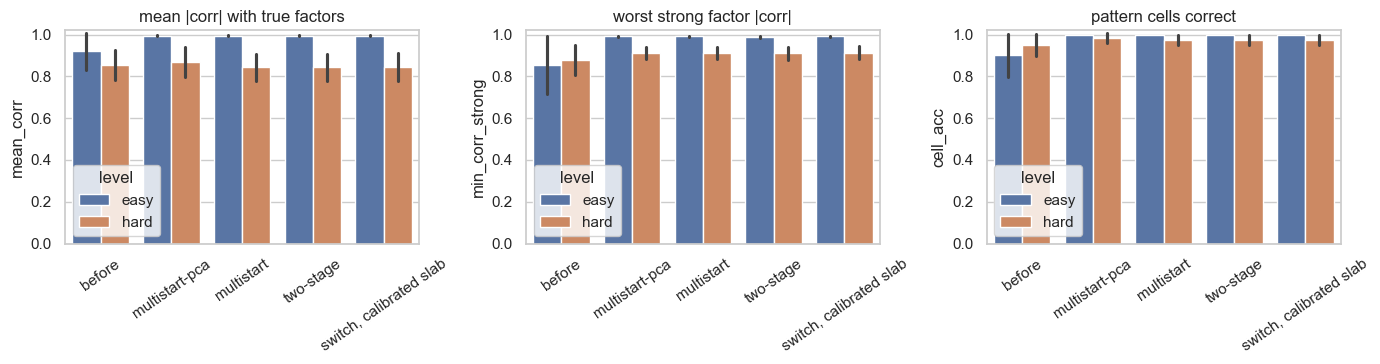

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, title in zip(axes, ["mean_corr", "min_corr_strong", "cell_acc"],
                          ["mean |corr| with true factors", "worst strong factor |corr|",
                           "pattern cells correct"]):
    sns.barplot(data=syn, x="arm", y=col, hue="level", order=order, ax=ax, errorbar="sd")
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35)
    ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

## 2 · Cohort π: does the scale-free paired prior remove the bias?

In [4]:
coh = im.run_cohort(seeds=range(3))
coh.to_csv(os.path.join(RESULTS, "improve_cohort.csv"), index=False)
print("all fits monotone:", bool(coh.monotone.all()))
coh.groupby(["level", "arm"])[["pi_err", "gamma_auc", "null_gamma", "alt_gamma", "min_corr"]].mean()

all fits monotone: True


pi_err  gamma_auc  null_gamma  \
level arm                                                                   
easy  after: + reference cohort              0.163      0.619       0.650   
      after: scale-free paired, learned pi   0.337      0.869       0.630   
      before: current q, fixed pi=0.5        0.208      0.841       0.458   
      before: current q, learned pi          0.291      0.864       0.586   
      paired q, learned pi (notebook 01)     0.235      0.873       0.487   
hard  after: + reference cohort              0.121      0.642       0.456   
      after: scale-free paired, learned pi   0.107      0.904       0.355   
      before: current q, fixed pi=0.5        0.244      0.883       0.148   
      before: current q, learned pi          0.138      0.755       0.085   
      paired q, learned pi (notebook 01)     0.105      0.904       0.332   

                                            alt_gamma  min_corr  
level arm                                                        
easy  after: + reference cohort                 0.821     0.646  
      after: scale-free paired, learned pi      0.972     0.648  
      before: current q, fixed pi=0.5           0.858     0.645  
      before: current q, learned pi             0.957     0.650  
      paired q, learned pi (notebook 01)        0.931     0.646  
hard  after: + reference cohort                 0.652     0.569  
      after: scale-free paired, learned pi      0.901     0.494  
      before: current q, fixed pi=0.5           0.754     0.471  
      before: current q, learned pi             0.531     0.468  
      paired q, learned pi (notebook 01)        0.893     0.498

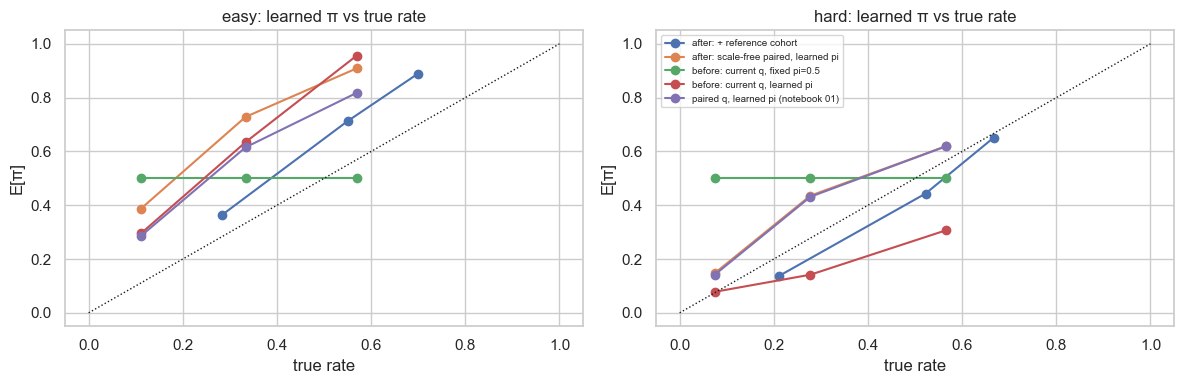

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, lv in zip(axes, ["easy", "hard"]):
    for arm, d in coh[coh.level == lv].groupby("arm"):
        g = d.groupby("rate")[["true_rate", "E_pi"]].mean()
        ax.plot(g["true_rate"], g["E_pi"], "o-", label=arm)
    ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_title(f"{lv}: learned π vs true rate")
    ax.set_xlabel("true rate"); ax.set_ylabel("E[π]")
axes[1].legend(fontsize=7); plt.tight_layout(); plt.show()

## 3 · Real data: seed stability and the final model's view pattern

In [6]:
DATA = {"COVID (M=2)": load_covid_views(top=150, cohort_mode="grouped"),
        "four-view (M=4)": load_four_view_cohort(top=100)}
K_REAL = {"COVID (M=2)": 5, "four-view (M=4)": 6}
real, refs = im.run_real(DATA, K_REAL, seeds=range(3), n_starts=4, max_iter=800)
real.to_csv(os.path.join(RESULTS, "improve_real.csv"), index=False)
real

,dataset,arm,activity_corr,mean_factor_match,min_factor_match,best_elbo
0,COVID (M=2),before,0.724,0.738,0.572,-127049.665
1,COVID (M=2),multistart,0.962,0.762,0.582,-124937.323
2,COVID (M=2),two-stage,0.977,0.862,0.624,-124508.490
3,four-view (M=4),before,0.898,0.785,0.580,-337790.106
4,four-view (M=4),multistart,1.000,0.999,0.999,-337449.848
5,four-view (M=4),two-stage,1.000,1.000,1.000,-339601.302


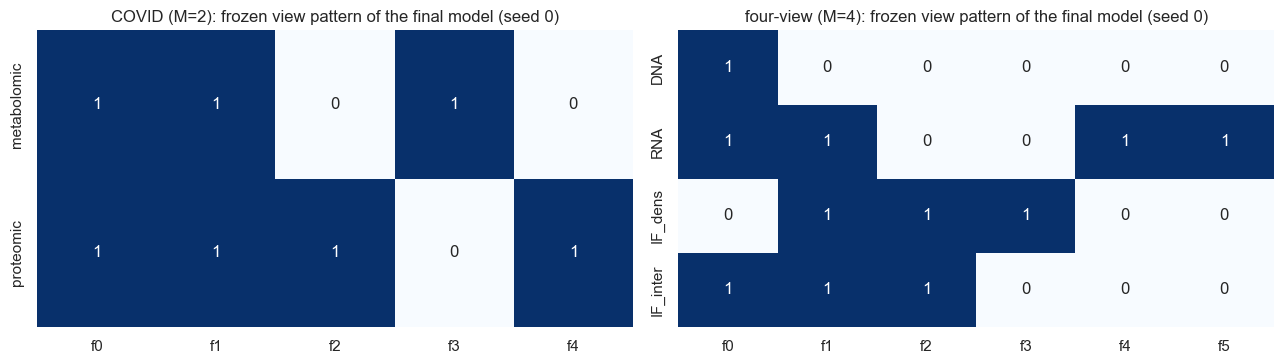

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, name in zip(axes, DATA):
    H = refs[(name, "two-stage")]["H"]
    sns.heatmap(H, ax=ax, cmap="Blues", cbar=False, annot=True,
                yticklabels=DATA[name].view_names, xticklabels=[f"f{k}" for k in range(H.shape[1])])
    ax.set_title(f"{name}: frozen view pattern of the final model (seed 0)")
plt.tight_layout(); plt.show()

In [8]:
rc = im.run_real_cohort(DATA, K_REAL)
rc.to_csv(os.path.join(RESULTS, "improve_real_cohort.csv"), index=False)
rc

,dataset,arm,E_pi,sd_pi,frac_on,frac_off,monotone
0,COVID (M=2),"before: current q, learned pi",0.918,0.065,1.000,0.000,True
1,COVID (M=2),"paired q, learned pi (notebook 01)",0.517,0.118,0.400,0.467,True
2,COVID (M=2),"after: scale-free paired, learned pi",0.598,0.116,0.467,0.067,True
3,four-view (M=4),"before: current q, learned pi",0.969,0.028,1.000,0.000,True
4,four-view (M=4),"paired q, learned pi (notebook 01)",0.885,0.051,0.833,0.000,True
5,four-view (M=4),"after: scale-free paired, learned pi",0.905,0.047,0.833,0.000,True
